<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>

# Histograms

Check out the video for full details, but here is also a great write-up: http://www.cambridgeincolour.com/tutorials/histograms1.htm

In [104]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Image Histograms with OpenCV

Recall that Matplotlib expects the images in a different RGB ordering vs BGR in OpenCV, so if we use OpenCV to calculate anything channel oriented, we'll want to make sure we keep the original RGB ordering, however if we ever want to display the image, then we'll need to convert to the RGB ordering that matplotlib wants.

----

In [105]:
dark_horse = cv2.imread('data/horse.jpg')
show_horse = cv2.cvtColor(dark_horse, cv2.COLOR_BGR2RGB)   # Only for visualization purpose

rainbow = cv2.imread('data/rainbow.jpg')
show_rainbow =cv2.cvtColor(rainbow, cv2.COLOR_BGR2RGB)     # Only for visualization purpose

blue_bricks = cv2.imread('data/bricks.jpg')
show_bricks = cv2.cvtColor(blue_bricks, cv2.COLOR_BGR2RGB) # Only for visualization purpose

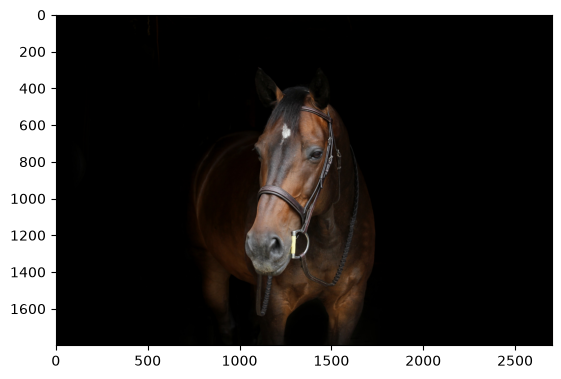

In [106]:
plt.imshow(show_horse)

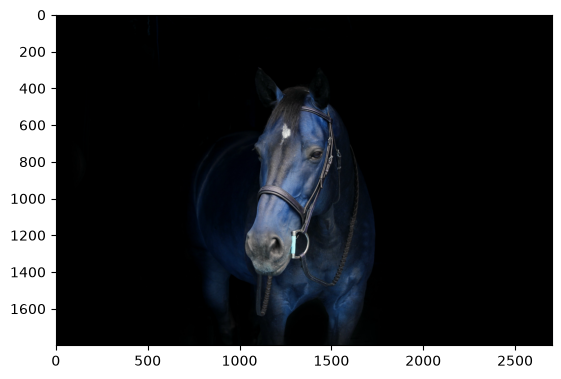

In [107]:
# RECALL MATPLOTLIB IMSHOW EXPECTS THE RGB IN A DIFFERENT ORDER!
# WATCH VIDEO FOR FULL DETAILS PLEASE!
plt.imshow(dark_horse)

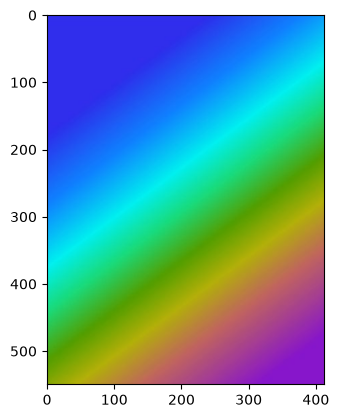

In [108]:
 plt.imshow(rainbow)

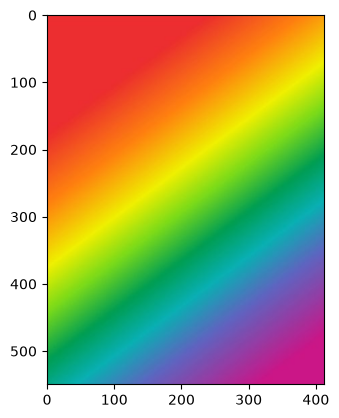

In [109]:
plt.imshow(show_rainbow)

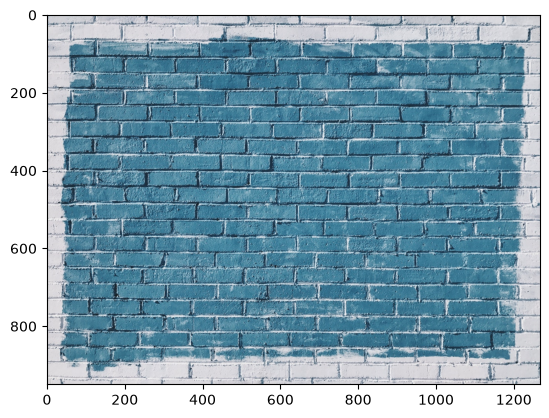

In [110]:
plt.imshow(show_bricks)

### OpenCV Histogram

**cv2.calcHist(images, channels, mask, histSize, ranges[, hist[, accumulate]])**

* images : it is the source image of type uint8 or float32. it should be given in square brackets, ie, “[img]”.
* channels : it is also given in square brackets. It is the index of channel for which we calculate histogram. For example, if input is grayscale image, its value is [0]. For color image, you can pass [0], [1] or [2] to calculate histogram of blue, green or red channel respectively.
* mask : mask image. To find histogram of full image, it is given as “None”. But if you want to find histogram of particular region of image, you have to create a mask image for that and give it as mask. (I will show an example later.)
* histSize : this represents our BIN count. Need to be given in square brackets. For full scale, we pass [256].
* ranges : this is our RANGE. Normally, it is [0,256].

In [111]:
hist_val = cv2.calcHist(images = [blue_bricks], 
                        channels = [0], # only for blue channel
                        mask = None, 
                        histSize = [256], 
                        ranges = [0,256])
hist_val.shape

(256, 1)

In [112]:
hist_val

array([[0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [1.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [0.0000e+00],
       [2.0000e+00],
       [0.0000e+00],
       [4.0000e+00],
       [1.0000e+00],
       [4.0000e+00],
       [0.0000e+00],
       [1.0000e+00],
       [1.0000e+00],
       [2.0000e+00],
       [5.0000e+00],
       [6.0000e+00],
       [5.0000e+00],
       [6.0000e+00],
       [8.0000e+00],
       [5.0000e+00],
       [1.1000e+01],
       [8.0000e+00],
       [1.4000e+01],
       [1.6000e+01],
       [1.8000e+01],
       [1.8000e+01],
       [2.2000e+01],
       [2.6000e+01],
       [3.7000e+01],
       [3.6000e+01],
       [4.6000e+01],
       [4.9000e+01],
       [5.6000e+01],
       [8.2000e+01],
       [8.7000e+01],
       [9.7000e+01],
       [1.150

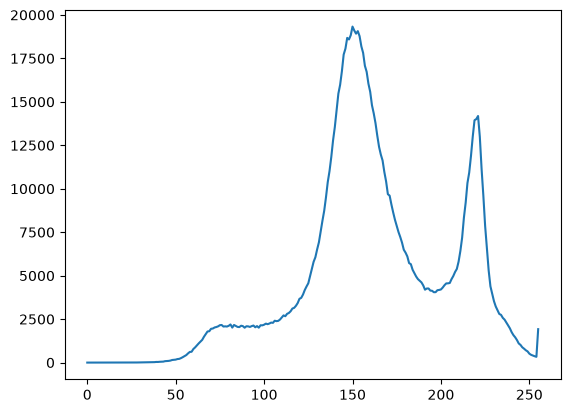

In [113]:
plt.plot(hist_val)

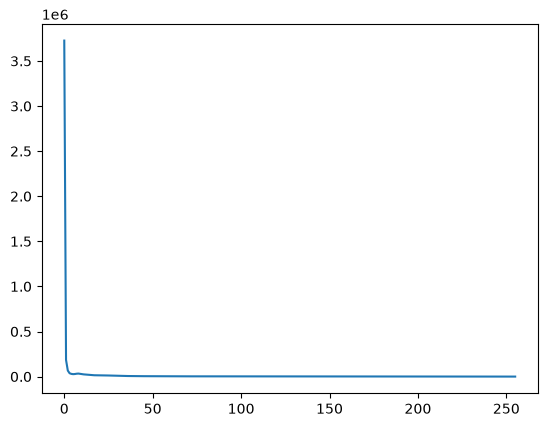

In [114]:
hist_val = cv2.calcHist(images = [dark_horse], 
                        channels = [0], # only for blue channel 
                        mask = None, 
                        histSize = [256], 
                        ranges = [0,256])
plt.plot(hist_val)

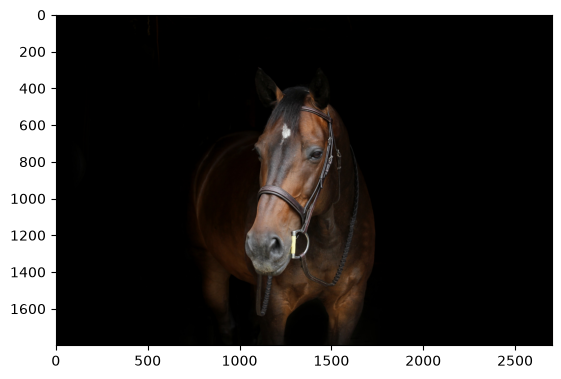

In [115]:
plt.imshow(show_horse)

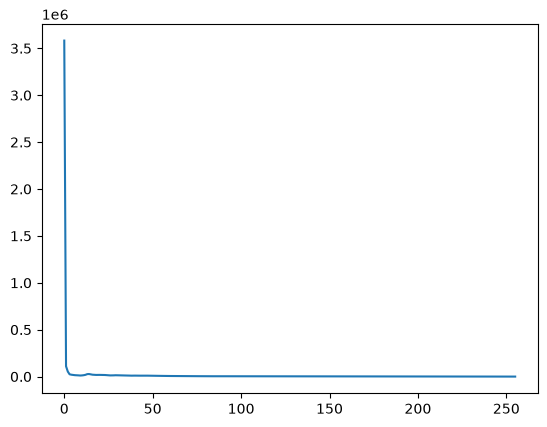

In [116]:
hist_val = cv2.calcHist(images = [show_horse], 
                        channels = [0], # only for blue channel
                        mask = None, 
                        histSize = [256], 
                        ranges = [0,256])
plt.plot(hist_val)

## Plotting 3 Color Histograms

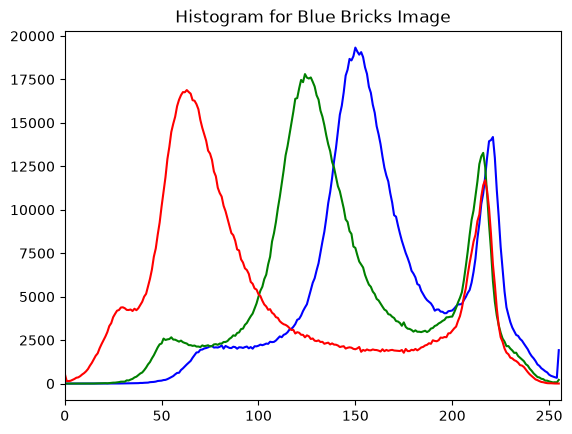

In [117]:
img = blue_bricks
color = ('b','g','r')

for i, col in enumerate(color):
    hist = cv2.calcHist([img], [i], None, [256], [0,256])
    plt.plot(hist, color=col)
    plt.xlim([0,256])

plt.title("Histogram for Blue Bricks Image")
plt.show()

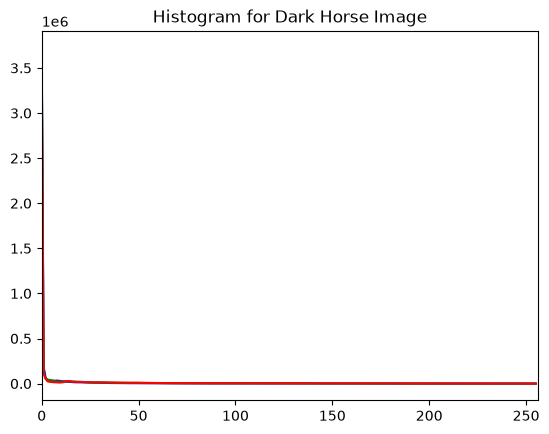

In [118]:
img = dark_horse
color = ('b','g','r')

for i, col in enumerate(color):
    hist = cv2.calcHist([img], [i], None, [256], [0,256])
    plt.plot(hist, color=col)
    plt.xlim([0,256])
    # plt.ylim([0,1.5])

plt.title("Histogram for Dark Horse Image")
plt.show()

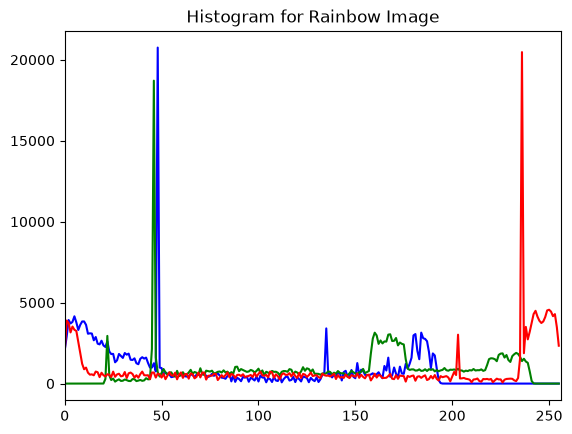

In [119]:
img = rainbow
color = ('b','g','r')

for i, col in enumerate(color):
    hist = cv2.calcHist([img], [i], None, [256], [0,256])
    plt.plot(hist, color=col)
    plt.xlim((0,256))

plt.title("Histogram for Rainbow Image")
plt.show()

### Masking

We can mask only certain parts of the image.

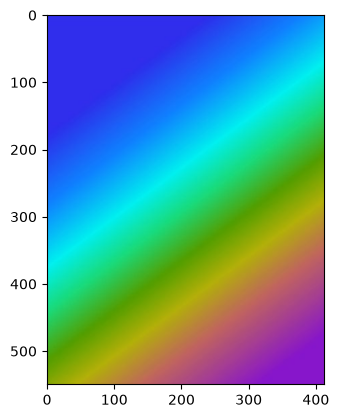

In [120]:
img = rainbow
plt.imshow(img)

In [121]:
img.shape

(550, 413, 3)

In [122]:
img.shape[:2]

(550, 413)

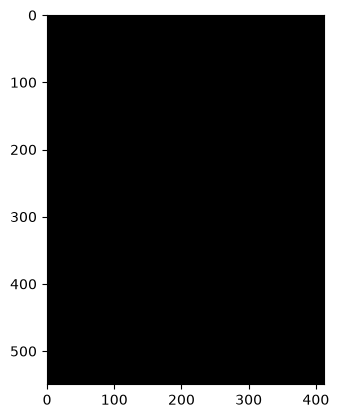

In [123]:
# Create a mask
mask = np.zeros(img.shape[:2], np.uint8)
plt.imshow(mask, 'gray')

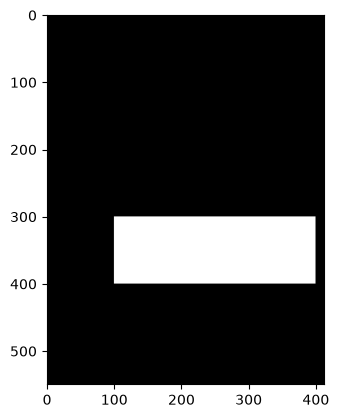

In [124]:
mask[300:400, 100:400] = 255
plt.imshow(mask, 'gray')

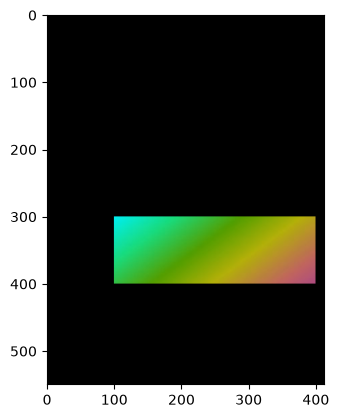

In [125]:
# For actual histogram calculation
masked_img = cv2.bitwise_and(img, img, mask=mask)
plt.imshow(masked_img)

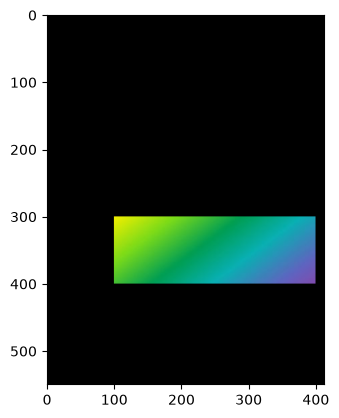

In [126]:
# For visualization purpose
show_masked_img = cv2.bitwise_and(show_rainbow, show_rainbow, mask=mask)
plt.imshow(show_masked_img)

In OpenCV, 

0 $\Rightarrow$ **Blue**   
1 $\Rightarrow$ **Green**   
2 $\Rightarrow$ **Red**  

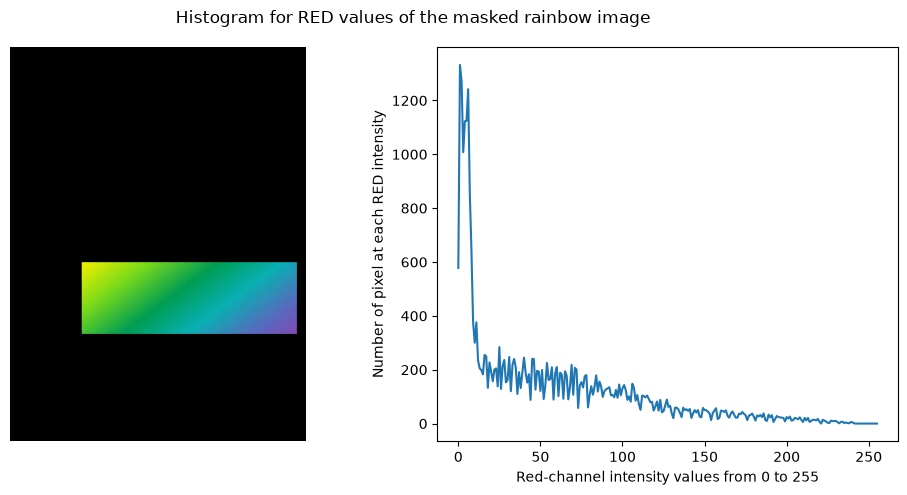

In [127]:
hist_mask_values_red = cv2.calcHist(images = [rainbow], 
                                    channels = [2], 
                                    mask = mask,        # only count the frequency of pixel in the masked region
                                    histSize = [256], 
                                    ranges = [0,256])
fig, x = plt.subplots(1,2, figsize=(10,5))
x[0].imshow(show_masked_img)
x[0].axis('off')
x[1].plot(hist_mask_values_red)
x[1].set_ylabel("Number of pixel at each RED intensity")
x[1].set_xlabel("Red-channel intensity values from 0 to 255")
plt.suptitle("Histogram for RED values of the masked rainbow image")
plt.tight_layout()
plt.show()

# RED intensity values are mostly seen some colors approaching to the dark side.

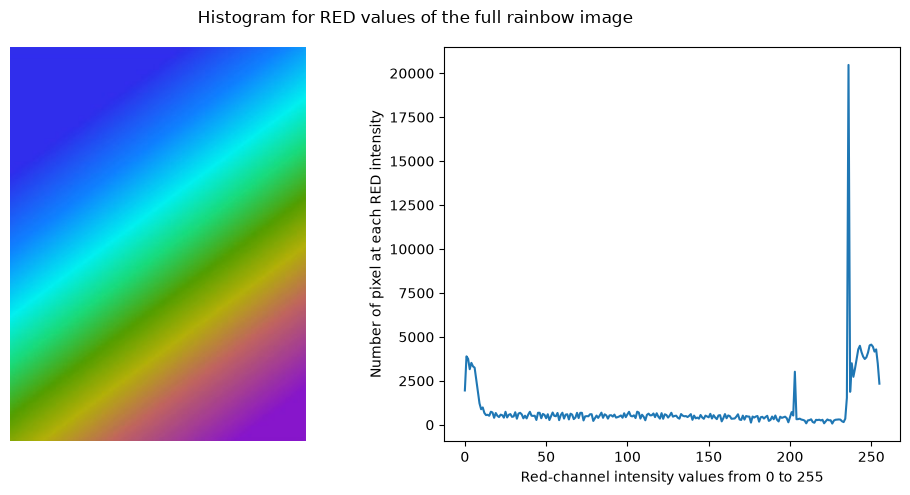

In [128]:
hist_full_values_red = cv2.calcHist(images = [rainbow], 
                                    channels = [2], 
                                    mask = None, 
                                    histSize = [256], 
                                    ranges = [0,256])
fig, x = plt.subplots(1,2, figsize=(10,5))
x[0].imshow(rainbow)
x[0].axis('off')
x[1].plot(hist_full_values_red)
x[1].set_ylabel("Number of pixel at each RED intensity")
x[1].set_xlabel("Red-channel intensity values from 0 to 255")
plt.suptitle("Histogram for RED values of the full rainbow image")
plt.tight_layout()
plt.show()

# RED intensity values are mostly seen in some color approaching to the white.

# Histogram Equalization

Make sure to watch the video and also read: https://en.wikipedia.org/wiki/Histogram_equalization

In [129]:
gorilla = cv2.imread('data/gorilla.jpg', 0)

In [130]:
def display(img, cmap=None):
    plt.figure(figsize=(10,8))
    plt.imshow(img,cmap)

## Single Channel (Grayscale)

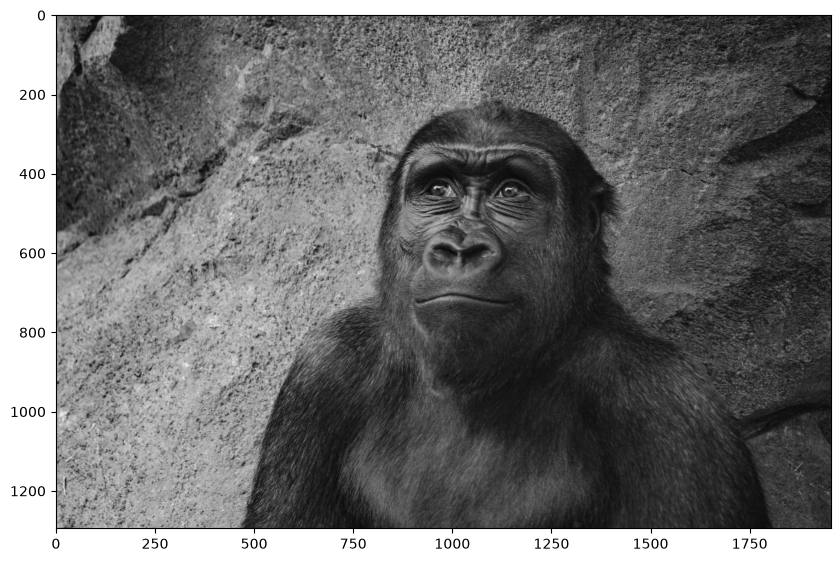

In [131]:
display(gorilla, cmap='gray')

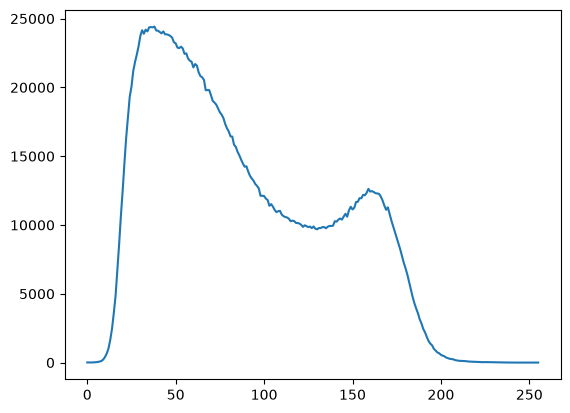

In [132]:
hist_values = cv2.calcHist(images = [gorilla], 
                           channels = [0],  # only for black channel (gray scale)
                           mask = None, 
                           histSize = [256], 
                           ranges = [0,256])
plt.plot(hist_values)
# The decreasement is deeped.

> **Important**: `cv2.equalizeHist()` expects a single-channel, 8-bit grayscale image (uint8). It is not intended to be applied directly to a three-channel color image.

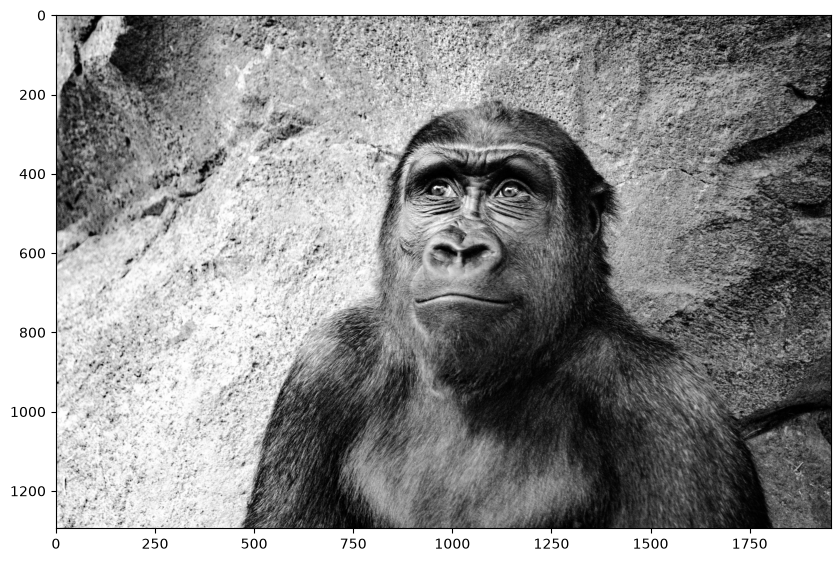

In [133]:
eq_gorilla = cv2.equalizeHist(gorilla)
display(eq_gorilla, 'gray')

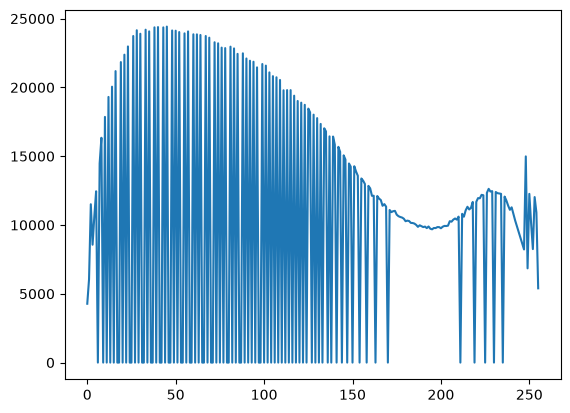

In [134]:
hist_values = cv2.calcHist(images = [eq_gorilla], 
                           channels = [0],  # only for black channel (gray scale)
                           mask = None, 
                           histSize = [256], 
                           ranges = [0,256])
plt.plot(hist_values)
# After equalization, the decreasement is shallower.

## Color Images

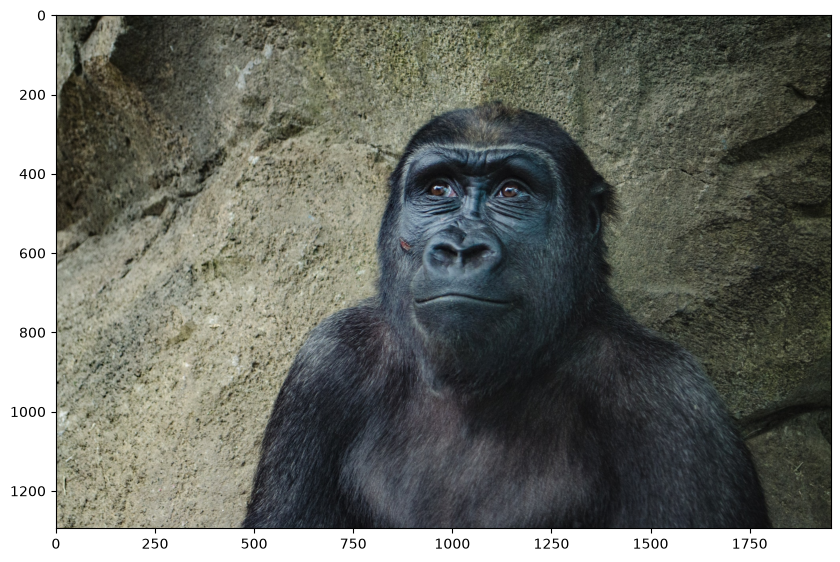

In [135]:
color_gorilla = cv2.imread('data/gorilla.jpg')
show_gorilla = cv2.cvtColor(color_gorilla, cv2.COLOR_BGR2RGB)
display(show_gorilla)

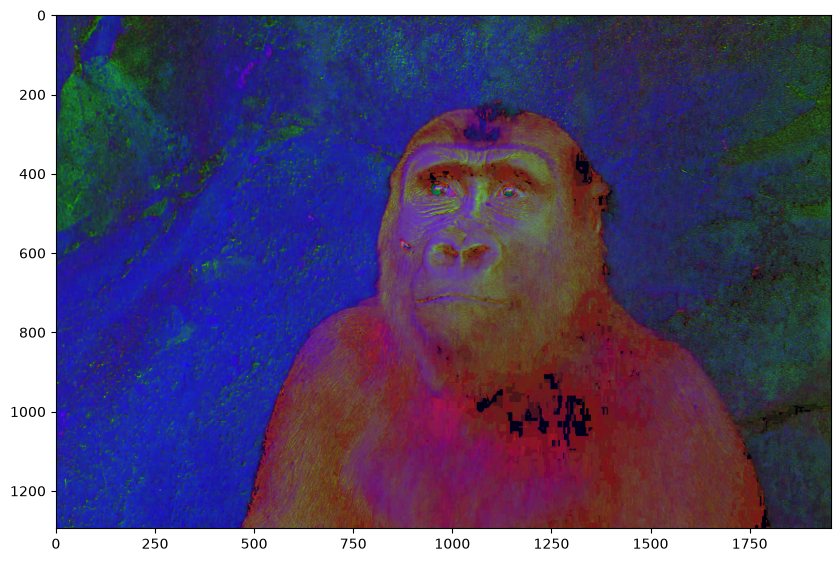

In [136]:
# Convert to HSV colorspace
hsv = cv2.cvtColor(src=color_gorilla, code=cv2.COLOR_BGR2HSV)
display(hsv)

**HSV channels**  
0 $\Rightarrow$ **Hue channel**  
1 $\Rightarrow$ **Saturation channel**  
2 $\Rightarrow$ **Value channel**

In [137]:
# Grab V channel
hsv[:,:,2]

array([[127, 121, 115, ...,  43,  42,  42],
       [121, 124, 123, ...,  47,  49,  51],
       [118, 129, 131, ...,  47,  50,  53],
       ...,
       [196, 198, 185, ...,  55,  55,  55],
       [184, 185, 182, ...,  51,  52,  53],
       [174, 170, 173, ...,  49,  50,  50]],
      shape=(1295, 1955), dtype=uint8)

In [138]:
hsv[:,:,2].min(), hsv[:,:,2].max()

(np.uint8(1), np.uint8(255))

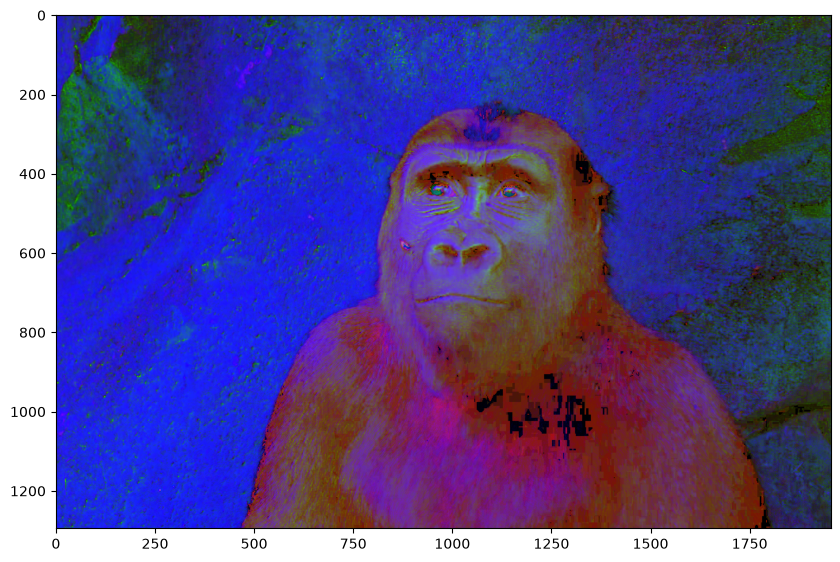

In [139]:
hsv[:, :, 2] = cv2.equalizeHist(hsv[:,:,2])
display(hsv)
# The blue channel pixel is getting higher.

In [140]:
hsv[:,:,2] = cv2.equalizeHist(hsv[:,:,2])

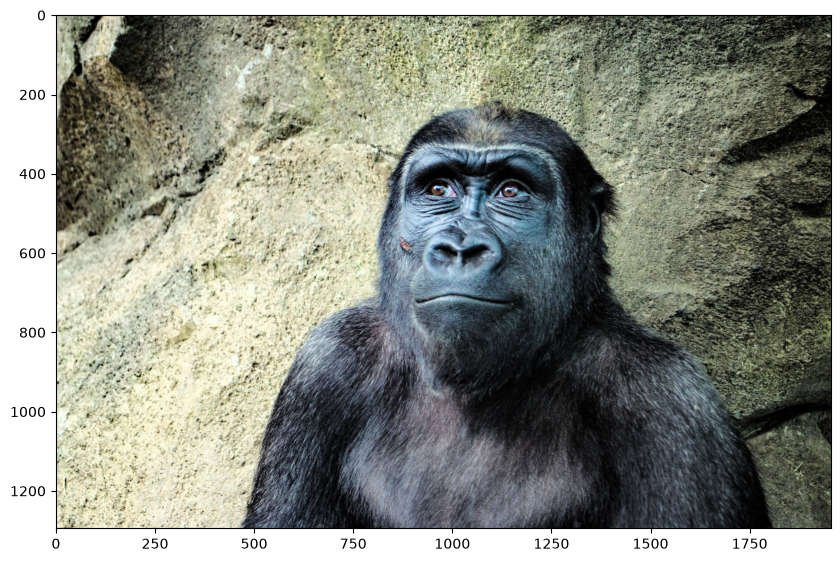

In [141]:
# Convert back to RGB for visualization
eq_color_gorilla = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
display(eq_color_gorilla)